In [1]:
import sys
sys.path.append("..")

import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
)
from src.data import load_data
from src.config import ROOT, TEST_DIR, FIG_DIR, MODEL_DIR
from src.pipelines import get_final
from src.bootstrap import ci_report

# Tải dữ liệu train và test
X_train, X_test, y_train, y_test, labels = load_data()

# Khởi tạo mô hình cuối cùng và huấn luyện trên tập train
model = get_final()
start_time = time.time()
model.fit(X_train, y_train)
fit_time = time.time() - start_time

print("Thoi gian fit:", round(fit_time, 1), "giay")

# Dự đoán thử trên tập train để kiểm tra Macro-F1
pred_train = model.predict(X_train)
train_macro_f1 = f1_score(y_train, pred_train, average="macro")
print("Macro-F1 tren train:", round(train_macro_f1, 4))

Thoi gian fit: 55.9 giay
Macro-F1 tren train: 0.9984


In [4]:
# CHI CHAY CELL NAY MOT LAN
pred = model.predict(X_test)
proba = model.predict_proba(X_test)
y_true = y_test.to_numpy()
n = len(y_true)

ket_qua = {
    "macro_f1": f1_score(y_true, pred, average="macro", labels=list(range(12)), zero_division=0),
    "balanced_acc": balanced_accuracy_score(y_true, pred),
    "mcc": matthews_corrcoef(y_true, pred),
    "accuracy": accuracy_score(y_true, pred),
    "weighted_f1": f1_score(y_true, pred, average="weighted", zero_division=0),
    "fit_time_s": fit_time,
}
pd.Series(ket_qua).round(4).to_csv(TEST_DIR / "final_metrics.csv", header=["gia_tri"])

pd.DataFrame({
    "y_true": y_true,
    "y_pred": pred,
    "proba_du_doan": proba.max(axis=1),
    "proba_lop_that": proba[np.arange(n), y_true],
}).to_csv(TEST_DIR / "final_predictions.csv", index=False)

joblib.dump(model, MODEL_DIR / "final_model.joblib")
(ROOT / "app").mkdir(exist_ok=True)
(ROOT / "app" / "feature_columns.json").write_text(
    json.dumps(list(X_train.columns)), encoding="utf-8")
(ROOT / "app" / "labels.json").write_text(
    json.dumps(list(labels), ensure_ascii=False), encoding="utf-8")

print(pd.Series(ket_qua).round(4))

macro_f1         0.9951
balanced_acc     0.9957
mcc              0.9967
accuracy         0.9986
weighted_f1      0.9986
fit_time_s      55.9308
dtype: float64


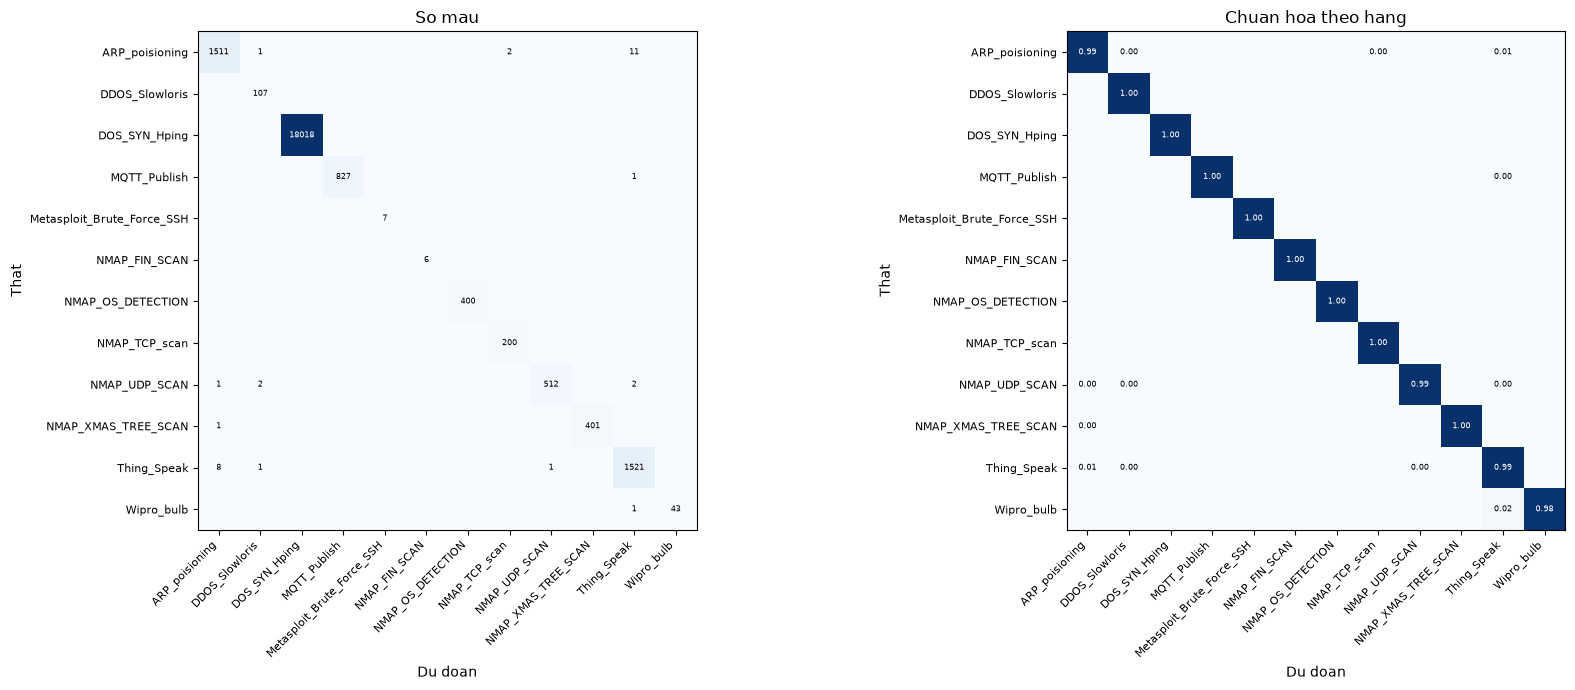

Macro-F1 test: 0.9951 CI 95% tu 0.9918 den 0.9975


,lop,so_mau_test,recall,recall_ci_thap,recall_ci_cao,precision,precision_ci_thap,precision_ci_cao,f1
0,ARP_poisioning,1525,0.9908,0.9860,0.9953,0.9934,0.9887,0.9973,0.9921
1,DDOS_Slowloris,107,1.0000,1.0000,1.0000,0.9640,0.9252,0.9915,0.9817
2,DOS_SYN_Hping,18018,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,MQTT_Publish,828,0.9988,0.9962,1.0000,1.0000,1.0000,1.0000,0.9994
4,Metasploit_Brute_Force_SSH,7,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
5,NMAP_FIN_SCAN,6,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
6,NMAP_OS_DETECTION,400,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
7,NMAP_TCP_scan,200,1.0000,1.0000,1.0000,0.9901,0.9744,1.0000,0.9950
8,NMAP_UDP_SCAN,517,0.9903,0.9812,0.9980,0.9981,0.9940,1.0000,0.9942
9,NMAP_XMAS_TREE_SCAN,402,0.9975,0.9917,1.0000,1.0000,1.0000,1.0000,0.9988


In [5]:
# Tính ma trận nhầm lẫn (12 lớp) và phiên bản chuẩn hóa theo hàng (tỷ lệ % trên từng lớp thật)
cm = confusion_matrix(y_true, pred, labels=list(range(12)))
row_sums = cm.sum(axis=1, keepdims=True)
cm_chuan = cm / row_sums

# Vẽ 2 biểu đồ cạnh nhau: số lượng mẫu và tỷ lệ chuẩn hóa theo hàng
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
plot_configs = [
    (axes[0], cm, "So mau", "d"),
    (axes[1], cm_chuan, "Chuan hoa theo hang", ".2f"),
]

for ax, data, title, fmt in plot_configs:
    ax.imshow(data, cmap="Blues")
    ax.set_xticks(range(12))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(12))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("Du doan")
    ax.set_ylabel("That")
    ax.set_title(title)

    # Ghi giá trị lên từng ô có giá trị lớn hơn 0
    half_max = data.max() / 2
    for i in range(12):
        for j in range(12):
            v = data[i, j]
            if v > 0:
                if v > half_max:
                    text_color = "white"
                else:
                    text_color = "black"
                label_text = format(v, fmt)
                ax.text(j, i, label_text, ha="center", va="center", fontsize=6, color=text_color)

plt.tight_layout()
plt.savefig(FIG_DIR / "final_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Tính Macro-F1 và khoảng tin cậy bootstrap 95% trên tập test
macro, bang = ci_report(y_true, pred, labels, n_boot=1000)
f1_val = round(macro["macro_f1"], 4)
ci_low = round(macro["ci_thap"], 4)
ci_high = round(macro["ci_cao"], 4)
print("Macro-F1 test:", f1_val, "CI 95% tu", ci_low, "den", ci_high)

# Lưu bảng kết quả tổng quan và từng lớp ra file CSV
macro_series = pd.Series(macro).round(4)
macro_series.to_csv(TEST_DIR / "final_macro_ci.csv", header=["gia_tri"])
bang.to_csv(TEST_DIR / "final_per_class_ci.csv", index=False)

bang